# NexaHR — LangGraph Agent Workflow

This notebook visualizes and explains the **actual backend graph** used by the NexaHR employee-support assistant. It imports the compiled graph from `app.rag.workflow`; it does not create a separate example workflow.

The agent answers HR questions using the private company knowledge base first. If that evidence is weak, it falls back to public web search, grades that evidence, and can rewrite/retry the query before returning a grounded answer or an insufficient-evidence response.

> Run this notebook from the repository root using the project's Python environment. Rendering the graph uses LangGraph's Mermaid renderer and may require an internet connection. Drawing the graph does not call an LLM or retrieve company documents.

## Architecture and decision flow

1. **`route_question`** — a LangChain chat model returns a structured `RouteDecision`: `kb` for HR/company questions or `direct` for greetings and casual chat.
2. **Direct branch** — `direct_answer` responds without retrieval and ends the run.
3. **Private knowledge branch** — `retrieve_kb` embeds the current query and retrieves the configured top-*k* chunks from the Pinecone HR namespace. `grade_kb` evaluates whether those chunks specifically answer the original question.
4. **Strong private evidence** — `generate_from_kb` answers only from the retrieved private evidence and adds private-KB citations.
5. **Weak private evidence** — `search_web` invokes Tavily, then `grade_web` evaluates public evidence. `generate_from_web` clearly identifies the answer as external information, not company policy.
6. **Weak web evidence** — `rewrite_query` improves the search/retrieval query and loops back to `retrieve_kb` while the configured retry limit allows. If the limit is reached, `insufficient` returns a cautious response rather than inventing policy.

### State passed through the graph

`AgentState` carries the original and rewritten question, retrieved documents, web results, evidence grades, answer, selected source, retry count, trace messages, and citations. Each node returns only the state fields it updates; LangGraph merges those updates as the run progresses.

### LangChain components

- **Chat model:** Groq is used when configured; OpenAI is the configured fallback. Router and evidence-grader outputs use typed structured output.
- **Private retrieval:** LangChain's retriever interface wraps the Pinecone vector store and Hugging Face sentence-transformer embeddings.
- **Public fallback:** LangChain's Tavily search integration supplies external results and URLs.
- **Orchestration:** LangGraph `StateGraph` defines the nodes, conditional branches, retry loop, and terminal paths.

The backend implementation is in `app/rag/workflow.py`; the state and structured output models are in `app/rag/state.py`. Secrets are loaded from local configuration and are not displayed by this notebook.

f:\MCA-Projects\NexaHR---Employee-Support-AI\.venv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


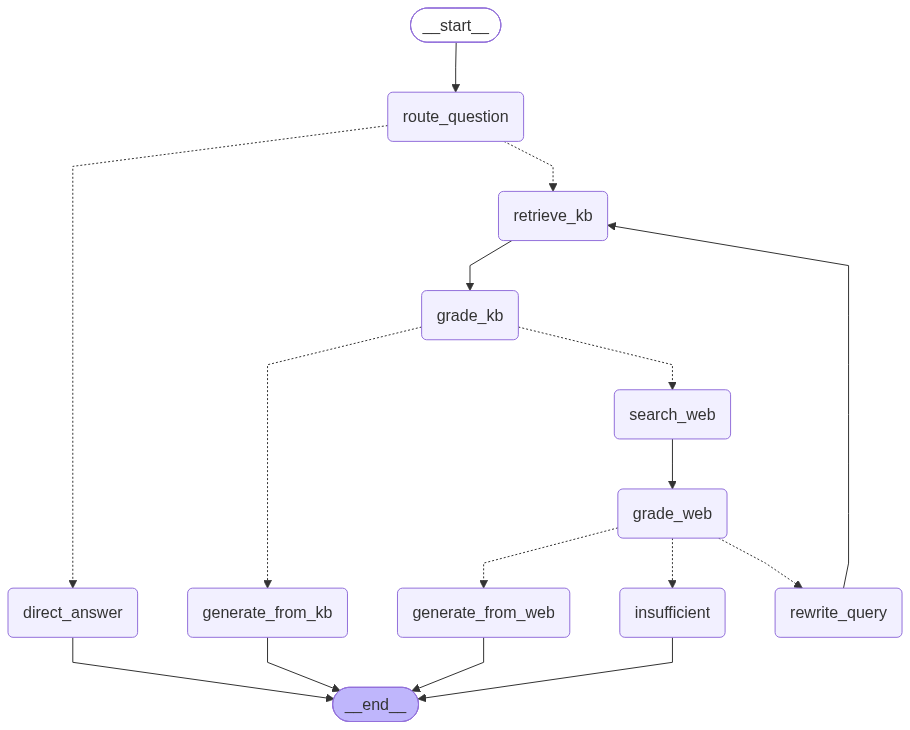

Graph nodes: __end__, __start__, direct_answer, generate_from_kb, generate_from_web, grade_kb, grade_web, insufficient, retrieve_kb, rewrite_query, route_question, search_web
AgentState fields: question, current_query, kb_docs, web_results, kb_grade, web_grade, answer, source_used, retry_count, trace, citations
Private retriever: Pinecone namespace='company-hr-kb', top_k=4
Embedding model: sentence-transformers/all-MiniLM-L6-v2
Maximum rewrite retries: 1
Configured chat provider: Groq (openai/gpt-oss-120b); API key value is hidden.


In [1]:
from typing import get_type_hints

from IPython.display import Image, Markdown, display

from app.core.config import get_settings
from app.rag.state import AgentState
from app.rag.workflow import agent_graph

# Render the same compiled graph that the FastAPI backend invokes.
compiled_view = agent_graph.get_graph()
display(Image(data=compiled_view.draw_mermaid_png(), format="png"))

settings = get_settings()
print("Graph nodes:", ", ".join(sorted(compiled_view.nodes)))
print("AgentState fields:", ", ".join(get_type_hints(AgentState)))
print(f"Private retriever: Pinecone namespace={settings.pinecone_namespace!r}, top_k={settings.top_k}")
print(f"Embedding model: {settings.embedding_model}")
print(f"Maximum rewrite retries: {settings.max_retries}")

if settings.groq_api_key.strip():
    print(f"Configured chat provider: Groq ({settings.groq_model}); API key value is hidden.")
elif settings.openai_api_key.strip():
    print(f"Configured chat provider: OpenAI ({settings.openai_model}); API key value is hidden.")
else:
    print("No chat provider key detected. Configure GROQ_API_KEY or OPENAI_API_KEY before running live queries.")

## How to present this workflow

- The graph is **evidence-first**: company policy answers prefer the private HR knowledge base.
- A separate grading decision makes the fallback explicit instead of treating every retrieval result as trustworthy.
- The retry edge is bounded by `max_retries`, so weak evidence cannot cause an endless loop.
- The final `source_used`, citations, and trace make it possible to explain where an answer came from.
- Public web results are not authoritative company policy; the web-answer prompt tells the user to validate them with HR.

The employee leave-balance profile in the Streamlit frontend is a separate local demonstration feature; it is not retrieved from this LangGraph/Pinecone workflow.

In [ ]:
# Optional integration demo. Leave False to avoid calling Groq/OpenAI, Pinecone, or Tavily.
# Set True only after configuring the required API keys and private knowledge index.
RUN_LIVE_QUERY = False
QUESTION = "What is the remote work policy?"

if RUN_LIVE_QUERY:
    from app.rag.workflow import ask

    result = ask(QUESTION)
    print("Answer:\n", result["answer"])
    print("\nFinal source:", result["source_used"])
    print("\nAgent trace:")
    for step in result["trace"]:
        print(" -", step)
    print("\nCitations:", result["citations"])